# Chapter 13: Categories

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 13.1 Bars of Averages

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='ticks')
plt.style.use('book.mplstyle')

In [2]:
orders = pd.read_csv('orders.csv')
orders.head(4)

,order_id,product,channel,order_value
0,1001,Mouse,Phone,30
1,1002,Keyboard,Online,52
2,1003,Headphones,Online,52
3,1004,Mouse,Online,20


### `sns.barplot()`

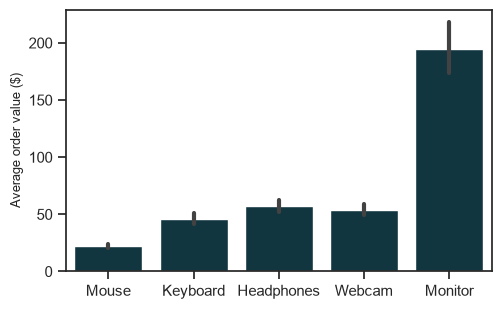

In [3]:
solid = {'linestyle': '-'}
ax = sns.barplot(data=orders, x='product', y='order_value',
                 err_kws=solid)
ax.set(xlabel='', ylabel='Average order value ($)')
plt.show()

In [4]:
orders.groupby('product')['order_value'].mean().round(1)

product
Headphones     57.2
Keyboard       46.2
Monitor       195.1
Mouse          22.6
Webcam         54.1
Name: order_value, dtype: float64

### Error bars

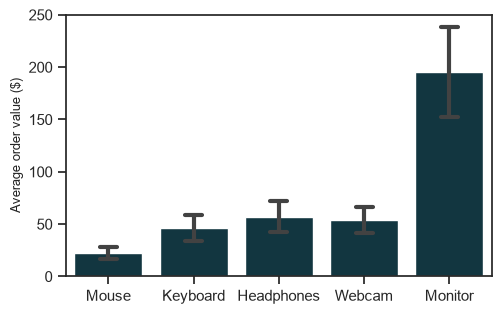

In [5]:
ax = sns.barplot(data=orders, x='product', y='order_value',
                 errorbar='sd', capsize=0.2, err_kws=solid)
ax.set(xlabel='', ylabel='Average order value ($)')
plt.show()

### Sorting, flipping and highlighting

In [6]:
by_value = (orders.groupby('product')['order_value']
            .mean().sort_values(ascending=False).index)

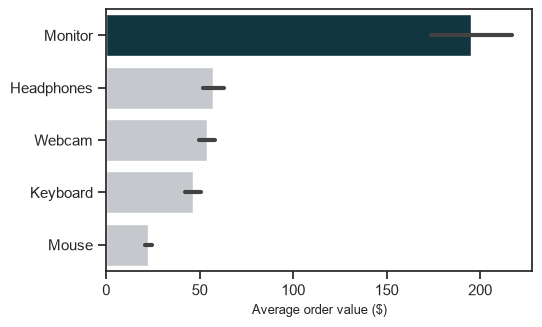

In [7]:
highlight = {'Monitor': '#0b3a47', 'Headphones': '#c4c9ce',
             'Webcam': '#c4c9ce', 'Keyboard': '#c4c9ce',
             'Mouse': '#c4c9ce'}
ax = sns.barplot(data=orders, y='product', x='order_value',
                 order=by_value, hue='product', palette=highlight,
                 legend=False, err_kws=solid)
ax.set(ylabel='', xlabel='Average order value ($)')
plt.show()

### `estimator=`

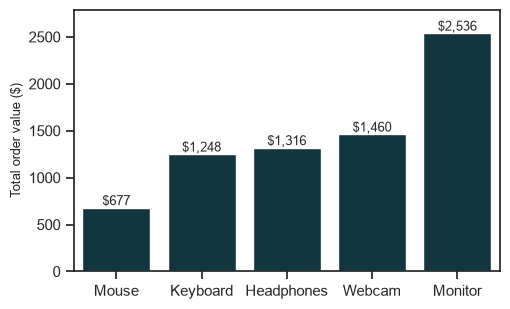

In [8]:
ax = sns.barplot(data=orders, x='product', y='order_value',
                 estimator='sum', errorbar=None)
ax.bar_label(ax.containers[0], fmt='${:,.0f}')
ax.margins(y=0.1)
ax.set(xlabel='', ylabel='Total order value ($)')
plt.show()

### Splitting bars with `hue=`

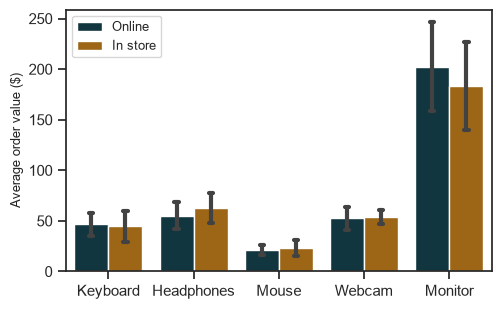

In [9]:
two_channels = orders[orders['channel'].isin(['Online', 'In store'])]
ax = sns.barplot(data=two_channels, x='product', y='order_value',
                 hue='channel', hue_order=['Online', 'In store'],
                 errorbar='sd', capsize=0.1, err_kws=solid)
ax.set(xlabel='', ylabel='Average order value ($)')
ax.legend(title='', loc='upper left')
plt.show()

## 13.2 Counting with `countplot()`

### `sns.countplot()`

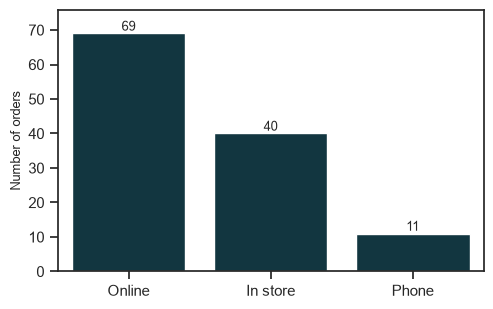

In [10]:
by_count = orders['channel'].value_counts().index
ax = sns.countplot(data=orders, x='channel', order=by_count)
ax.bar_label(ax.containers[0])
ax.margins(y=0.1)
ax.set(xlabel='', ylabel='Number of orders')
plt.show()

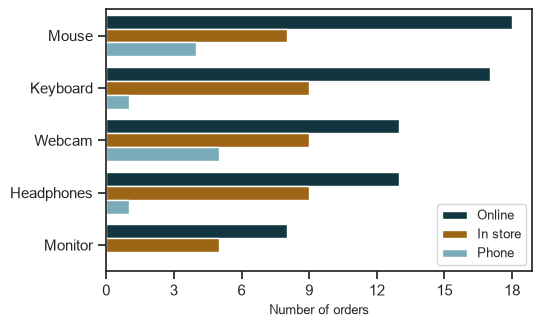

In [11]:
by_product = orders['product'].value_counts().index
ax = sns.countplot(data=orders, y='product', order=by_product,
                   hue='channel', hue_order=['Online', 'In store',
                                              'Phone'])
ax.set(ylabel='', xlabel='Number of orders', xticks=range(0, 19, 3))
ax.legend(title='', loc='lower right')
plt.show()

## 13.3 Showing Every Order with `stripplot()`

### `sns.stripplot()`

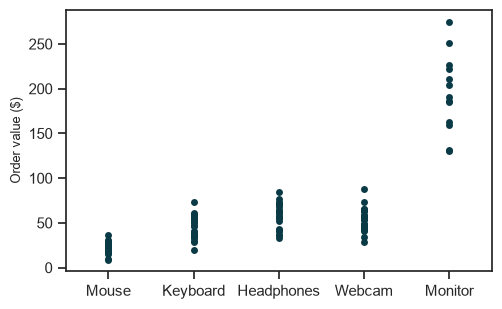

In [12]:
ax = sns.stripplot(data=orders, x='product', y='order_value',
                   jitter=False)
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

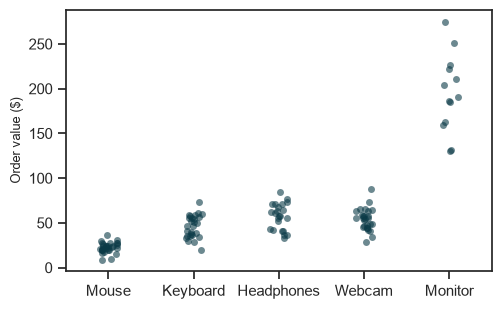

In [13]:
ax = sns.stripplot(data=orders, x='product', y='order_value',
                   alpha=0.6)
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

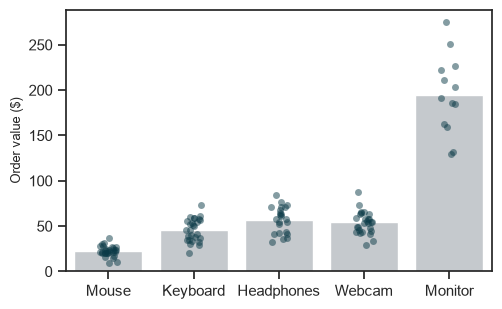

In [14]:
ax = sns.barplot(data=orders, x='product', y='order_value',
                 errorbar=None, color='#c4c9ce')
sns.stripplot(data=orders, x='product', y='order_value',
              color='#0b3a47', alpha=0.5, ax=ax)
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

## 13.4 Boxes and Violins

### `sns.boxplot()`

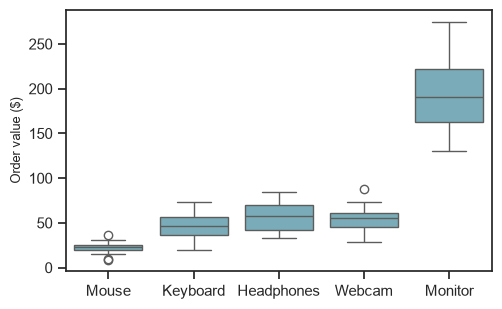

In [15]:
ax = sns.boxplot(data=orders, x='product', y='order_value',
                 color='#6fb3c2')
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

### `sns.violinplot()`

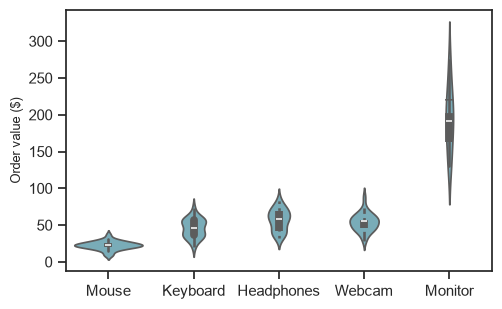

In [16]:
ax = sns.violinplot(data=orders, x='product', y='order_value',
                    color='#6fb3c2')
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

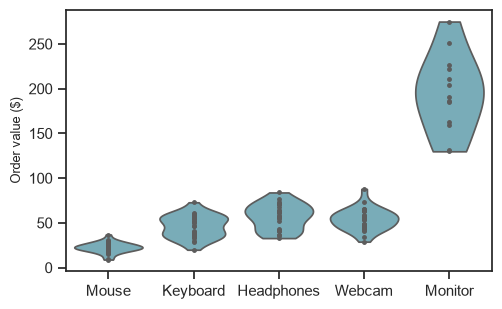

In [17]:
ax = sns.violinplot(data=orders, x='product', y='order_value',
                    color='#6fb3c2', cut=0, density_norm='width',
                    inner='point')
ax.set(xlabel='', ylabel='Order value ($)')
plt.show()

## 13.5 One Function for All: `catplot()`

### `sns.catplot()`

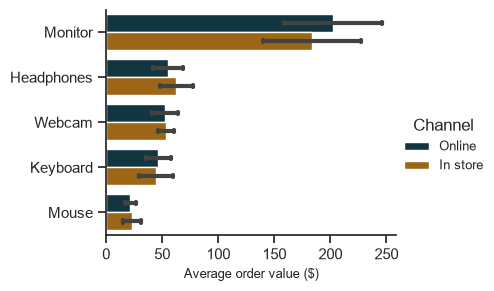

In [18]:
g = sns.catplot(data=two_channels, kind='bar', y='product',
                x='order_value', order=by_value, hue='channel',
                hue_order=['Online', 'In store'], errorbar='sd',
                capsize=0.1, err_kws=solid, height=3, aspect=1.5)
g.set_axis_labels('Average order value ($)', '')
g.legend.set_title('Channel')
plt.show()